# A Commercial Real Estate Cover Pool: Loan-Level ML Distress Model, VAE Macro Scenarios and Required Overcollateralisation

Commercial mortgages are repaid from rents and usually have to be refinanced at maturity, which is exactly what failed for many office loans when rates rose in 2023. When such loans back a covered bond, the issuer has to hold extra collateral to absorb that risk. This notebook builds a cover pool from real loans and works out how much extra collateral it needs.

**What it does.** It builds a hypothetical covered bond cover pool from about 540 real U.S. commercial mortgages and stress-tests it. The loans come from the current loan-level tapes (SEC Form ABS-EE) of fifteen 2024 conduit CMBS trusts.

**Distress model.** A LightGBM model with monotonic constraints is trained on nine years of quarterly loan tapes from fourteen 2016–2017 conduit trusts. It predicts the 12-month probability that a performing loan becomes **distressed** (60+ days delinquent, non-performing at maturity, transferred to special servicing or liquidated).

Its features are DSCR, NOI and occupancy trends, marked-to-market LTV, maturity, property type and the macro state. The model is validated **out of time** on 2023–2025, the office and higher-rates stress.

**Macro scenarios.** A Keras **variational autoencoder** learns the joint one-year moves of CRE prices, Treasury yields, corporate spreads, unemployment and bank CRE delinquencies (FRED, 1991–2026) and generates thousands of coherent scenarios.

**Stress test.** Each scenario is pushed through the loans:

- property values and NOI are shocked;
- term-default probabilities come from the model;
- loans maturing within the horizon face a **refinancing test**, the classic covered-bond risk.

The output is a three-year loss distribution and the **overcollateralisation the pool needs** at each confidence level. It is reported for the full loans and for a Pfandbrief-style pool that only counts each loan up to 60% of the property's lending value.

**Data.** SEC EDGAR ABS-EE (EX-102 CMBS asset data) and FRED (CRE price index, 10-year Treasury, Baa spread, unemployment, CRE delinquency rate).

**Methods.** A loan-quarter panel, LightGBM with monotonic constraints, a logistic regression benchmark, out-of-time validation, SHAP, a variational autoencoder (Keras 3) and a Monte Carlo credit-loss simulation.

## 1. Commercial mortgages as cover collateral

Most European covered bonds are backed by residential mortgages. Several frameworks also allow **commercial real estate** in the cover pool:
- the German Pfandbrief;
- Austria, Sweden, Spain and others;
- the EU Covered Bond Directive, for loans backed by commercial immovable property.

CRE loans are riskier than residential mortgages for four reasons:
- **income-driven:** the borrower repays from rents, so NOI and the debt service coverage ratio (DSCR) matter more than the borrower's own credit;
- **lumpy:** a few large loans dominate;
- **bullet:** most are interest-only or lightly amortising, so the balance must be **refinanced at maturity**. Refinancing fails when values have fallen or rates have risen, which is exactly the 2023–2025 office story;
- **cyclical:** values move with rates and spreads.

Frameworks respond with **LTV caps on the eligible amount**. The Pfandbrief only counts a commercial loan up to 60% of the mortgage lending value, a prudent value below market value. Issuers and agencies then add OC sized by a stress test. This notebook builds that stress test from data.

**Why CMBS data.** European cover pools are not published loan by loan. US conduit CMBS trusts are: every month each trust files a standard loan tape with the SEC. The tape covers balance, rate, maturity, property type, valuation, occupancy, NOI, DSCR, payment status, special servicing and liquidation losses. That makes it the best public loan-level history of commercial mortgage performance.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
os.environ.setdefault("KERAS_BACKEND", "torch")

# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import keras
import lightgbm as lgb
import shap
from keras import layers, ops
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    roc_auc_score,
    roc_curve,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

warnings.filterwarnings(
    "ignore", message=".*TreeExplainer shap values output has changed.*"
)
SEED = 31
rng = np.random.default_rng(SEED)
keras.utils.set_random_seed(SEED)
if not os.getenv("SEC_USER_AGENT"):
    raise RuntimeError(
        "SEC_USER_AGENT not found in .env (EDGAR requires a declared"
        " User-Agent: 'Name email')."
    )
# Training history: 2016–2017 conduit trusts (quarterly loan tapes since
# issuance)
# Wells Fargo Commercial Mortgage Trust 2016–2017
TRAIN_CIKS = [
    1688957,
    1707817,
    1710798,
    1716187,
    1719199,
    1723291,
    1699462,
    1695924,
    # BANK 2017
    1698685,
    1706303,
    1710261,
    1714679,
    1718322,
    1721373,
]
# Cover pool: latest tape of 2024 conduit trusts
# BANK5 2024
POOL_CIKS = [
    2037111,
    2041680,
    2044491,
    2006016,
    2022503,
    2012481,
    2032772,
    # Benchmark 2024
    2034418,
    2039535,
    2044630,
    2004982,
    2012265,
    2016841,
    2024274,
    2030476,
]
# out-of-time split with a one-year gap (labels look 4 quarters ahead)
TRAIN_END, TEST_START = pd.Period("2021Q4"), pd.Period("2023Q1")
HORIZON_YEARS = 3  # stress horizon
N_SCEN = 4000  # VAE macro scenarios
# foreclosure, carry and sale costs as a share of the stressed value
# (assumption)
LIQ_COST = 0.25
# mortgage lending value as a share of market value (assumption)
MLV_HAIRCUT = 0.85
# Pfandbrief-style cap on the eligible amount, share of lending value
ELIGIBLE_LTV = 0.60
REFI_DSCR, REFI_LTV, REFI_SPREAD = (
    1.25,
    0.75,
    0.020,
# refinancing test at maturity: new lender's DSCR and LTV limits, spread over the 10y
)
# value sensitivity to the CRE index (assumption)
VALUE_BETA = {
    "OF": 1.5,
    "RT": 1.2,
    "LO": 1.3,
    "MU": 1.1,
    "MF": 0.9,
    "IN": 0.9,
    "SS": 0.9,
    "MH": 0.8,
}
# NOI change per +1pp unemployment (assumption)
NOI_BETA = {
    "LO": -0.06,
    "RT": -0.03,
    "OF": -0.03,
    "MU": -0.03,
    "IN": -0.02,
    "SS": -0.02,
    "MF": -0.015,
    "MH": -0.01,
}
PTYPES = ["MF", "RT", "OF", "LO", "IN", "SS", "MH", "MU", "OT"]

print(
    f"keras {keras.__version__} ({keras.backend.backend()}) · lightgbm"
    f" {lgb.__version__} · shap {shap.__version__} · run on"
    f" {dt.date.today():%Y-%m-%d}"
)

keras 3.15.1 (torch) · lightgbm 4.7.0 · shap 0.54.1 · run on 2026-10-20


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"

## 3. Loan tapes from EDGAR

Each trust's ABS-EE filings are listed from the EDGAR submissions API. For the training trusts, the last filing of each quarter-end month is kept, which gives a quarterly panel from issuance to today. For the cover pool only the latest tape is needed.

Each EX-102 XML file has one `assets` record per loan, with the characteristics of its property. Multi-property loans also list one extra record per property; those records are dropped, so the loan keeps the characteristics of its first, largest property. Every parsed file is cached in `data/absee_cmbs/`.

In [3]:
import json
from lxml import etree

NS = "{http://www.sec.gov/edgar/document/absee/cmbs/assetdata}"
CMBS_DIR = DATA_DIR / "absee_cmbs"
CMBS_DIR.mkdir(parents=True, exist_ok=True)
LOAN = {
    "assetNumber": "asset",
    "reportingPeriodEndDate": "period_end",
    "originationDate": "orig_date",
    "originalLoanAmount": "orig_amt",
    "maturityDate": "maturity",
    "originalInterestRatePercentage": "rate",
    "originalInterestOnlyTermNumber": "io_term",
    "originalAmortizationTermNumber": "amort_term",
    "interestOnlyIndicator": "io",
    "originalInterestRateTypeCode": "rate_type",
    "reportPeriodEndActualBalanceAmount": "bal",
    "reportPeriodBeginningScheduleLoanBalanceAmount": "beg_bal",
    "paymentStatusLoanCode": "status",
    "mostRecentSpecialServicerTransferDate": "ss_date",
    "workoutStrategyCode": "workout",
    "modifiedIndicator": "modified",
    "liquidationPrepaymentCode": "liq_code",
    "realizedLossToTrustAmount": "loss",
    "NumberProperties": "n_props",
    "loanStructureCode": "structure",
    "originalTermLoanNumber": "orig_term",
    "totalPrincipalInterestAdvancedOutstandingAmount": "pi_adv",
}
PROP = {
    "propertyTypeCode": "ptype",
    "propertyState": "state",
    "yearBuiltNumber": "year_built",
    "valuationSecuritizationAmount": "value_sec",
    "mostRecentValuationAmount": "value_recent",
    "physicalOccupancySecuritizationPercentage": "occ_sec",
    "mostRecentPhysicalOccupancyPercentage": "occ_recent",
    "netOperatingIncomeSecuritizationAmount": "noi_sec",
    "mostRecentNetOperatingIncomeAmount": "noi_recent",
    "debtServiceCoverageNetCashFlowSecuritizationPercentage": "dscr_sec",
    "mostRecentDebtServiceCoverageNetCashFlowpercentage": "dscr_recent",
    "mostRecentFinancialsEndDate": "fin_date",
    "DefeasedStatusCode": "defeased",
    "netCashFlowFlowSecuritizationAmount": "ncf_sec",
    "mostRecentNetCashFlowAmount": "ncf_recent",
    "mostRecentDebtServiceAmount": "ds_recent",
    "leaseExpirationLargestTenantDate": "lease_exp_top",
}
CMBS_NUM = [
    "orig_amt",
    "rate",
    "io_term",
    "amort_term",
    "bal",
    "beg_bal",
    "loss",
    "n_props",
    "pi_adv",
    "year_built",
    "value_sec",
    "value_recent",
    "occ_sec",
    "occ_recent",
    "noi_sec",
    "noi_recent",
    "dscr_sec",
    "dscr_recent",
    "ncf_sec",
    "ncf_recent",
    "ds_recent",
    "orig_term",
]
SEC = requests.Session()


def sec_get(url, **kw):
    """
    GET from EDGAR with the declared User-Agent, retrying on timeouts and
    throttling.
    """
    for attempt in range(6):
        try:
            r = SEC.get(
                url,
                headers={"User-Agent": os.environ["SEC_USER_AGENT"]},
                timeout=(20, 180),
                **kw,
            )
            if r.status_code == 200:
                return r
        except requests.RequestException:
            pass
        time.sleep(3 + 5 * attempt)
    raise RuntimeError(f"EDGAR request failed: {url}")


def trust_filings(cik):
    """
    All ABS-EE filings of one CMBS trust: (filing date, URL of the EX-102 asset
    data file). Cached for 20 days.
    """
    cache = CMBS_DIR / f"filings_{cik}.json"
    if cache.exists() and time.time() - cache.stat().st_mtime < 20 * 86400:
        d = json.loads(cache.read_text())
        return d["name"], [tuple(x) for x in d["files"]]
    j = sec_get(f"https://data.sec.gov/submissions/CIK{cik:010d}.json").json()
    r = j["filings"]["recent"]
    out = []
    for i, form in enumerate(r["form"]):
        if form == "ABS-EE":
            acc = r["accessionNumber"][i].replace("-", "")
            out.append((
                r["filingDate"][i],
                f"https://www.sec.gov/Archives/edgar/data/{cik}/{acc}/exh_102.xml",
            ))
    cache.write_text(json.dumps({"name": j["name"], "files": sorted(out)}))
    return j["name"], sorted(out)


def parse_cmbs(url, dest):
    """
    Parse one CMBS EX-102 file: one row per loan, with the first (largest)
    property's characteristics.
    """
    try:
        content = sec_get(url).content
    # some filers name the exhibit differently: look it up in the filing index
    except RuntimeError:
        base = url.rsplit("/", 1)[0]
        items = sec_get(base + "/index.json").json()["directory"]["item"]
        xml = [
            it["name"]
            for it in items
            if it["name"].lower().endswith(".xml") and "103" not in it["name"]
        ]
        content = sec_get(f"{base}/{xml[0]}").content
    root = etree.fromstring(content)
    rows = []
    for a in root.iter(NS + "assets"):
        rec = {}
        for ch in a:
            tag = ch.tag.replace(NS, "")
            if tag in LOAN:
                rec[LOAN[tag]] = ch.text
            elif tag == "property" and "ptype" not in rec:
                for p in ch:
                    k = PROP.get(p.tag.replace(NS, ""))
                    if k:
                        rec[k] = p.text
        rows.append(rec)
    df = pd.DataFrame(rows)
    for c in CMBS_NUM:
        if c in df:
            df[c] = pd.to_numeric(df[c], errors="coerce")
    df.to_parquet(dest, index=False)
    return len(df)


def load_trusts(ciks, months=(3, 6, 9, 12), latest_only=False):
    """
    Loan-level panel for a list of trusts: quarterly filings (or only the
    latest), cached file by file.
    """
    parts = []
    for cik in ciks:
        try:
            name, files = trust_filings(cik)
        except Exception as err:
            print(f"  CIK {cik}: {type(err).__name__}, skipped")
            continue
        if not files:
            continue
        if latest_only:
            files = files[-1:]
        else:
            by_q = {}
            # last filing in each filing month of the chosen quarters
            for fdate, url in files:
                if int(fdate[5:7]) in months:
                    by_q[fdate[:7]] = (fdate, url)
            files = sorted(by_q.values())
        for fdate, url in files:
            dest = CMBS_DIR / f"{cik}_{fdate}.parquet"
            if not dest.exists():
                try:
                    parse_cmbs(url, dest)
                except Exception as err:
                    print(f"  {name} {fdate}: {type(err).__name__}, skipped")
                    continue
                time.sleep(0.12)
            d = pd.read_parquet(dest)
            d["cik"], d["trust"], d["filing_date"] = cik, name, fdate
            parts.append(d)
    return pd.concat(parts, ignore_index=True)


def tidy(raw):
    # drop property sub-records of multi-property loans
    d = raw[~raw["asset"].astype(str).str.contains("-")].copy()
    d["period"] = pd.to_datetime(
        d["period_end"], format="%m-%d-%Y", errors="coerce"
    )
    d["period"] = d["period"].fillna(pd.to_datetime(d["filing_date"]))
    d["q"] = d["period"].dt.to_period("Q")
    d["loan"] = d["cik"].astype(str) + "_" + d["asset"].astype(str)
    for c_ in ["orig_date", "maturity", "ss_date", "lease_exp_top"]:
        d[c_] = pd.to_datetime(d[c_], format="%m-%d-%Y", errors="coerce")
    d["ptype"] = d["ptype"].where(d["ptype"].isin(PTYPES), "OT").fillna("OT")
    return (
        d.sort_values(["loan", "q", "filing_date"])
        .drop_duplicates(["loan", "q"], keep="last")
        .reset_index(drop=True)
    )


hist = tidy(load_trusts(TRAIN_CIKS))
pool_raw = tidy(load_trusts(POOL_CIKS, latest_only=True))
print(
    f"Training tapes: {hist['trust'].nunique()} trusts ·"
    f" {hist['loan'].nunique():,} loans · {len(hist):,} loan-quarters ·"
    f" {hist['q'].min()} → {hist['q'].max()}"
)
print(
    f"Cover pool tapes: {pool_raw['trust'].nunique()} trusts ·"
    f" {pool_raw['loan'].nunique():,} loans"
)

Training tapes: 14 trusts · 1,083 loans · 28,574 loan-quarters · 2016Q4 → 2026Q3
Cover pool tapes: 15 trusts · 553 loans


## 4. Macro data and the loan-quarter panel

**Macro state.** All five series are quarterly and expressed as **one-year changes**:
- the Federal Reserve's CRE price index, as a log change;
- the 10-year Treasury yield;
- the Baa–Treasury spread;
- the unemployment rate;
- the bank CRE delinquency rate.

The loan model sees them lagged by one quarter, as a lender would.

**Distress.** A loan is distressed in a quarter if any of these holds:
- its payment status is 60+ days delinquent, 90+ days delinquent, or non-performing matured balloon;
- it is with the special servicer under an active workout strategy (modification, foreclosure, bankruptcy, note sale, discounted payoff, REO and similar; *resolved* and *pending return* do not count);
- it was liquidated or disposed of.

**Label.** For every performing, non-defeased loan with a balance at quarter *t*: does it become distressed in quarters *t+1* to *t+4*? Loans that pay off before that count as non-distressed.

**Pari passu notes.** Large loans are split into notes held by several trusts. The tape reports the trust's own note balance, but DSCR, NCF and the appraisal describe the whole loan. The whole-loan balance is recovered from the reported whole-loan debt service at securitisation (NCF / DSCR) divided by the note's own debt service. Every LTV and debt yield below uses it.

**Features at *t*:**
- most recent DSCR (NCF) and its change since securitisation;
- occupancy and its change;
- LTV at securitisation and **marked-to-market LTV**, with the appraisal rolled forward with the CRE price index;
- **debt yield** (NCF / whole-loan balance, computed as DSCR × the loan's debt constant so that year-to-date financials do not bias it), the **refinancing DSCR** (the interest-only DSCR the loan would have if refinanced today at the 10-year yield + 2%) and the **rate gap** between that market rate and the loan's coupon;
- months to maturity, loan age, the coupon's spread over the 10-year yield at origination (an absolute coupon would make every 2024 loan look risky), interest-only flag, loan size, building age;
- months to the largest tenant's lease expiry;
- property type and the macro state.

In [4]:
SERIES = {
    "cre_px": "BOGZ1FL075035503Q",
    "y10": "DGS10",
    "baa": "BAA10Y",
    "unemp": "UNRATE",
    "cre_dq": "DRCRELEXFACBS",
}


def fetch_macro():
    return (
        pd.DataFrame({
            k: fred.get_series(s).resample("QE").mean()
            for k, s in SERIES.items()
        })
        .rename_axis("date")
        .reset_index()
    )


mac = cached(
    "fred_macro_quarterly", fetch_macro, max_age_hours=24 * 7
).set_index("date")
mac.index = pd.to_datetime(mac.index).to_period("Q")
MACRO = pd.DataFrame({
    "cre_yoy": np.log(mac["cre_px"]).diff(4) * 100,
    "d10y": mac["y10"].diff(4),
    "dbaa": mac["baa"].diff(4),
    "dunemp": mac["unemp"].diff(4),
    "dcre_dq": mac["cre_dq"].diff(4),
})
MAC_FEATS = ["cre_yoy", "d10y", "dbaa", "dunemp"]
cre_level = mac["cre_px"].ffill()

DIST_STATUS, BAD_WORKOUT = {"2", "3", "5", "6"}, {
    "1",
    "2",
    "3",
    "5",
    "6",
    "7",
    "10",
    "12",
    "13",
    "98",
}
p = hist.copy()
p["distress"] = (
    p["status"].isin(DIST_STATUS)
    | (p["ss_date"].notna() & p["workout"].isin(BAD_WORKOUT))
    | p["liq_code"].isin(["3", "6"])
).astype(int)
p["qn"] = p["q"].dt.year * 4 + p["q"].dt.quarter


def annual_constant(r, amort_months):
    """
    Annual debt service per unit of balance: the rate for interest-only loans,
    the annuity payment otherwise.
    """
    r, n = np.asarray(r, float), np.asarray(amort_months, float)
    ann = (r / 12) / (1 - (1 + r / 12) ** -np.where(n > 0, n, 360)) * 12
    return np.where(n > 0, ann, r)


def whole_loan_multiple(d):
    """
    Pari passu notes: the trust holds one piece, while DSCR, NCF and value
    describe the whole loan.
    Whole-loan debt service at securitisation (NCF / DSCR) over the piece's own
    debt service gives the multiple.
    """
    ds_whole = d["ncf_sec"] / d["dscr_sec"]
    amort = np.where(
        d["io"].astype(str).str.lower().eq("true"),
        0,
        d["amort_term"].fillna(0),
    )
    ds_piece = d["orig_amt"] * annual_constant(d["rate"], amort)
    m = (ds_whole / ds_piece).where(lambda x: np.isfinite(x))
    return m.clip(1, 40).fillna(1.0)


def whole_loan_value(d):
    """
    Whole-loan balance and the property value backing it. Implied
    securitisation LTVs above 85% are data artefacts
    (multi-property loans report only the first property's appraisal), so those
    values are replaced by balance / 65%.
    """
    wb = d["bal"] * whole_loan_multiple(d)
    ltv0 = d["orig_amt"] * whole_loan_multiple(d) / d["value_sec"]
    value = d["value_sec"].where(
        (ltv0 > 0) & (ltv0 <= 0.85),
        d["orig_amt"] * whole_loan_multiple(d) / 0.65,
    )
    return wb, value


def features(d, macro_q):
    """
    Loan features at the reporting date; macro_q is the quarter whose macro
    state the lender knows.
    """
    f = pd.DataFrame(index=d.index)
    f["dscr"] = d["dscr_recent"].fillna(d["dscr_sec"]).clip(0, 8)
    f["dscr_chg"] = (d["dscr_recent"] / d["dscr_sec"] - 1).clip(-1, 3)
    f["occ"] = d["occ_recent"].fillna(d["occ_sec"]).clip(0, 1.2)
    f["occ_chg"] = (d["occ_recent"] - d["occ_sec"]).clip(-1, 1)
    wb, value = whole_loan_value(d)
    f["ltv_sec"] = (wb / value).clip(0, 3)
    idx_orig = cre_level.reindex(d["orig_date"].dt.to_period("Q")).to_numpy()
    idx_now = cre_level.reindex(macro_q).to_numpy()
    f["ltv_mtm"] = (wb / (value * idx_now / idx_orig)).clip(0, 3).to_numpy()
    amort = np.where(
        d["io"].astype(str).str.lower().eq("true"),
        0,
        d["amort_term"].fillna(0),
    )
    # NCF / whole-loan balance (DSCR × debt constant)
    f["debt_yield"] = (f["dscr"] * annual_constant(d["rate"], amort)).clip(
        -0.2, 0.5
    )
    y10 = mac["y10"].reindex(macro_q).to_numpy()
    f["refi_dscr"] = (f["debt_yield"] / (y10 / 100 + REFI_SPREAD)).clip(
        -1, 5
    )  # interest-only DSCR at today's market rate
    f["rate_gap"] = y10 + REFI_SPREAD * 100 - d["rate"].to_numpy() * 100
    f["months_to_mat"] = ((d["maturity"] - d["period"]).dt.days / 30.44).clip(
        -24, 240
    )
    f["loan_age"] = ((d["period"] - d["orig_date"]).dt.days / 30.44).clip(
        0, 400
    )
    # coupon over the 10y at origination
    f["orig_spread"] = (
        d["rate"].to_numpy() * 100
        - mac["y10"].reindex(d["orig_date"].dt.to_period("Q")).to_numpy()
    )
    f["io"] = d["io"].astype(str).str.lower().eq("true").astype(int)
    f["log_bal"] = np.log10(d["bal"].clip(lower=1e5))
    f["bldg_age"] = (d["period"].dt.year - d["year_built"]).clip(0, 150)
    f["lease_roll_m"] = (
        (d["lease_exp_top"] - d["period"]).dt.days / 30.44
    ).clip(-24, 240)
    f["ptype"] = pd.Categorical(d["ptype"], categories=PTYPES)
    m = MACRO.reindex(macro_q).to_numpy()
    for j, c_ in enumerate(MAC_FEATS):
        f[c_] = m[:, j]
    return f


perf = p[
    (p["bal"] > 0)
    & (p["distress"] == 0)
    & (p["defeased"] != "F")
    & (p["status"].isin(["0", "A", "B", "1"]))
].copy()
lab = np.zeros(len(perf))
dist = p[["loan", "qn", "distress"]]
for k in range(1, 5):
    nxt = (
        perf[["loan", "qn"]]
        .assign(qn=perf["qn"] + k)
        .merge(dist, on=["loan", "qn"], how="left")["distress"]
        .fillna(0)
        .to_numpy()
    )
    lab = np.maximum(lab, nxt)
perf["y"] = lab
# the label needs four quarters of future tapes
perf = perf[perf["q"] <= p["q"].max() - 4]
X = features(perf, perf["q"] - 1)
y = perf["y"].to_numpy().astype(int)
FEATS = list(X.columns)
print(
    f"Panel: {len(perf):,} performing loan-quarters ·"
    f" {perf['loan'].nunique():,} loans · 12-month distress rate"
    f" {y.mean():.2%} · {p.loc[p['distress'] == 1, 'loan'].nunique()} loans"
    " ever distressed"
)
perf.assign(y=y).groupby("ptype", observed=True)["y"].agg(
    ["size", "mean"]
).sort_values("mean", ascending=False).round(4)

Panel: 22,644 performing loan-quarters · 856 loans · 12-month distress rate 1.59% · 102 loans ever distressed


,size,mean
ptype,,
LO,2627,0.05
OF,3136,0.03
MU,918,0.02
MF,1692,0.02
RT,6998,0.01
MH,753,0.01
IN,878,0.00
OT,3673,0.00
SS,1969,0.00


## 5. The distress model and its out-of-time test

**Models:**
- **LightGBM** with **monotonic constraints**, so a lower DSCR, higher LTV, falling CRE prices, rising yields, spreads or unemployment can only raise the predicted risk. The constraints make the model safe to push into stress scenarios beyond the training data;
- **logistic regression** on the same standardised features with property-type dummies;
- a **DSCR-only** rule, the benchmark a credit officer would use.

All three are trained on quarters up to 2021-Q4 and tested on 2023-Q1 onwards. For contrast, a 5-fold cross-validation that holds out random loans across all periods measures the model's skill *within* a known regime. The test period is the rate-shock and office-distress period the training data never saw. Metrics are AUC, PR-AUC (distress is rare) and the Brier score. A **calibration** check compares predicted and realised rates by decile.

In [5]:
MONO = {
    "dscr": -1,
    "dscr_chg": -1,
    "occ": -1,
    "ltv_mtm": 1,
    "ltv_sec": 1,
    "debt_yield": -1,
    "refi_dscr": -1,
    "rate_gap": 1,
    "cre_yoy": -1,
    "d10y": 1,
    "dbaa": 1,
    "dunemp": 1,
}
mono = [MONO.get(f_, 0) for f_ in FEATS]
GB = dict(
    n_estimators=500,
    learning_rate=0.02,
    num_leaves=15,
    min_child_samples=60,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    reg_lambda=5.0,
    monotone_constraints=mono,
    monotone_constraints_method="advanced",
    verbose=-1,
    random_state=SEED,
)
tr, te = (perf["q"] <= TRAIN_END).to_numpy(), (
    perf["q"] >= TEST_START
).to_numpy()
gb = lgb.LGBMClassifier(**GB).fit(X[tr], y[tr])
NUMF = [f_ for f_ in FEATS if f_ != "ptype"]


def lr_design(Xd, med):
    Z = Xd[NUMF].fillna(med)
    return pd.concat(
        [Z, pd.get_dummies(Xd["ptype"], prefix="pt", dtype=float)], axis=1
    )


med = X.loc[tr, NUMF].median()
lr = make_pipeline(
    StandardScaler(), LogisticRegression(C=0.5, max_iter=3000)
).fit(lr_design(X[tr], med), y[tr])
preds = {
    "LightGBM (monotonic)": gb.predict_proba(X[te])[:, 1],
    "logistic regression": lr.predict_proba(lr_design(X[te], med))[:, 1],
    "DSCR only": (
        -X.loc[te, "dscr"].fillna(X.loc[tr, "dscr"].median()).to_numpy()
    ),
}
yt = y[te]
oot = pd.DataFrame({
    k: {
        "AUC": roc_auc_score(yt, v),
        "PR-AUC": average_precision_score(yt, v),
        "Brier": brier_score_loss(yt, v) if k != "DSCR only" else np.nan,
    }
    for k, v in preds.items()
}).T
oot.loc["base rate"] = [
    0.5,
    yt.mean(),
    brier_score_loss(yt, np.full(len(yt), y[tr].mean())),
]
cal = pd.DataFrame({"pd": preds["LightGBM (monotonic)"], "y": yt})
cal["decile"] = pd.qcut(cal["pd"].rank(method="first"), 10, labels=False) + 1
cal_t = cal.groupby("decile").agg(
    predicted=("pd", "mean"), realised=("y", "mean"), n=("y", "size")
)
from sklearn.model_selection import GroupKFold

cv_pred = np.zeros(len(y))
# in-regime check: random loans held out, all periods mixed
for a_, b_ in GroupKFold(5).split(X, y, groups=perf["loan"]):
    cv_pred[b_] = (
        lgb.LGBMClassifier(**GB)
        .fit(X.iloc[a_], y[a_])
        .predict_proba(X.iloc[b_])[:, 1]
    )
print(
    "In-regime AUC (5-fold, loans grouped, all periods):"
    f" {roc_auc_score(y, cv_pred):.2f}"
)
# final model for the stress test uses all history
gb_all = lgb.LGBMClassifier(**GB).fit(X, y)
sv = shap.TreeExplainer(gb_all).shap_values(X)
sv = sv[1] if isinstance(sv, list) else sv
shap_imp = pd.Series(np.abs(sv).mean(0), index=FEATS).sort_values(
    ascending=False
)
print(
    f"Train {tr.sum():,} obs (distress {y[tr].mean():.2%}) · test"
    f" {te.sum():,} obs (distress {yt.mean():.2%})"
)
display(oot.round(4))
display(cal_t.round(4))
shap_imp.round(3).to_frame("mean |SHAP| (log-odds)").head(12)

In-regime AUC (5-fold, loans grouped, all periods): 0.89


Train 13,301 obs (distress 1.28%) · test 6,509 obs (distress 2.69%)


,AUC,PR-AUC,Brier
LightGBM (monotonic),0.60,0.11,0.03
logistic regression,0.57,0.05,0.03
DSCR only,0.59,0.04,NaN
base rate,0.50,0.03,0.03


,predicted,realised,n
decile,,,
1,0.00,0.04,651
2,0.00,0.02,651
3,0.00,0.00,651
4,0.00,0.01,651
5,0.00,0.02,651
6,0.00,0.02,650
7,0.00,0.03,651
8,0.01,0.02,651
9,0.01,0.03,651


,mean |SHAP| (log-odds)
orig_spread,0.47
dunemp,0.40
ptype,0.35
log_bal,0.23
occ_chg,0.23
bldg_age,0.22
loan_age,0.22
ltv_sec,0.20
months_to_mat,0.17
occ,0.15


## 6. Macro scenarios from a variational autoencoder

The scenario generator learns the **joint distribution of one-year macro moves** from 1991–2026. Over that period:
- CRE prices fall about 35% in the GFC and about 15% in 2023–2024;
- yields jump in 2022;
- spreads blow out in 2008 and 2020.

**The model.** A small VAE on the five standardised changes: two latent dimensions, a 16-unit tanh encoder and decoder, β = 0.5 on the KL term. Scenarios are drawn from the **aggregate posterior**: pick a historical quarter at random, draw from its encoded latent distribution, decode, and add Gaussian residual noise with the reconstruction error's covariance.

The standard-normal prior of a VAE trained on 138 points under-represents the rare crisis quarters, and the decoder mean alone would understate dispersion.

**Benchmarks:**
- a multivariate **Gaussian**, which has the same correlations but thin tails;
- **historical** one-year moves.

The check is whether the VAE reproduces the co-movement of the tails: CRE prices down together with unemployment and spreads up.

In [6]:
VARS = ["cre_yoy", "d10y", "dbaa", "dunemp", "dcre_dq"]
H = MACRO[VARS].dropna()
H = H[H.index >= pd.Period("1991Q1")]
mu, sd = H.mean(), H.std()
Zh = ((H - mu) / sd).to_numpy("float32")


class KLSample(layers.Layer):
    """
    Reparameterised latent draw that adds the KL divergence to the model loss.
    """

    def __init__(self, beta=0.5, **kw):
        super().__init__(**kw)
        self.beta, self.gen = beta, keras.random.SeedGenerator(SEED)

    def call(self, inputs):
        m, lv = inputs
        self.add_loss(
            self.beta
            * ops.mean(-0.5 * ops.sum(1 + lv - m**2 - ops.exp(lv), axis=1))
        )
        return m + ops.exp(0.5 * lv) * keras.random.normal(
            ops.shape(m), seed=self.gen
        )


LAT = 2
xin = keras.Input((len(VARS),))
hid = layers.Dense(16, activation="tanh")(xin)
z_m, z_lv = layers.Dense(LAT)(hid), layers.Dense(LAT)(hid)
decoder = keras.Sequential(
    [
        keras.Input((LAT,)),
        layers.Dense(16, activation="tanh"),
        layers.Dense(len(VARS)),
    ],
    name="decoder",
)
encoder = keras.Model(xin, [z_m, z_lv], name="encoder")
vae = keras.Model(xin, decoder(KLSample(0.5)([z_m, z_lv])))
vae.compile(optimizer=keras.optimizers.Adam(3e-3), loss="mse")
hist_fit = vae.fit(Zh, Zh, epochs=1500, batch_size=32, verbose=0)
zm_h, zlv_h = encoder.predict(Zh, verbose=0)
resid = Zh - decoder.predict(zm_h, verbose=0)
Lc = np.linalg.cholesky(np.cov(resid.T) + 1e-6 * np.eye(len(VARS)))
pick = rng.integers(
    0, len(Zh), N_SCEN
)  # aggregate posterior: a random quarter's latent distribution
z_draw = zm_h[pick] + np.exp(0.5 * zlv_h[pick]) * rng.standard_normal(
    (N_SCEN, LAT)
)
gen = (
    decoder.predict(z_draw.astype("float32"), verbose=0)
    + rng.standard_normal((N_SCEN, len(VARS))) @ Lc.T
)
SCEN = pd.DataFrame(gen * sd.to_numpy() + mu.to_numpy(), columns=VARS)
GAUSS = pd.DataFrame(
    rng.multivariate_normal(mu, H.cov(), N_SCEN), columns=VARS
)


def tail_stats(D):
    q05 = D["cre_yoy"].quantile(0.05)
    t = D[D["cre_yoy"] <= q05]
    return pd.Series({
        "CRE 1% (log %)": D["cre_yoy"].quantile(0.01),
        "CRE 5%": q05,
        "unemp. 99%": D["dunemp"].quantile(0.99),
        "Baa 99%": D["dbaa"].quantile(0.99),
        "corr(CRE, unemp)": D["cre_yoy"].corr(D["dunemp"]),
        "mean Δunemp when CRE in worst 5%": t["dunemp"].mean(),
        "mean ΔBaa when CRE in worst 5%": t["dbaa"].mean(),
    })


tails = pd.DataFrame({
    "historical": tail_stats(H),
    "VAE": tail_stats(SCEN),
    "Gaussian": tail_stats(GAUSS),
})
print(
    f"VAE trained on {len(H)} quarterly one-year moves · final loss"
    f" {hist_fit.history['loss'][-1]:.3f}"
)
tails.round(2)

VAE trained on 138 quarterly one-year moves · final loss 0.875


,historical,VAE,Gaussian
CRE 1% (log %),-31.06,-24.74,-17.17
CRE 5%,-10.89,-11.57,-11.61
unemp. 99%,4.74,4.41,3.42
Baa 99%,2.09,1.74,1.73
"corr(CRE, unemp)",-0.52,-0.48,-0.52
mean Δunemp when CRE in worst 5%,2.23,2.49,1.82
mean ΔBaa when CRE in worst 5%,-0.16,-0.10,0.11


## 7. The cover pool and the stress engine

**Cover pool.** The latest tapes of the 2024 trusts, keeping performing, non-defeased loans with a balance. They are measured at today's macro state.

For each scenario *s* and loan *i* over a three-year horizon:
1. **Value.** The marked-to-market value is shocked by the scenario's CRE price move times a property-type beta. Office, lodging and retail are more sensitive than multifamily or industrial.
2. **NOI and DSCR.** NOI moves with unemployment through a property-type sensitivity, and the DSCR scales with it.
3. **Term default.** The distress model is re-scored with the stressed DSCR, debt yield, refinancing DSCR, LTV and macro features. The one-year probability compounds to three years.
4. **Refinancing default.** A loan maturing within the horizon must refinance at the stressed 10-year yield plus a 2% spread. A new lender requires an interest-only DSCR ≥ 1.25 and LTV ≤ 75%. A loan that fails defaults at maturity: no extension is assumed, which is the conservative covered-bond view.
5. **Loss.** Defaults are drawn independently given the scenario. Loss given default is the balance minus the stressed value net of 25% liquidation costs, floored at zero.

**Two pool definitions:**
- **full loans:** all balances count as cover;
- **eligible:** each loan counts only up to 60% of its mortgage lending value, taken as 85% of market value at securitisation. On default, recoveries first cover the eligible part, as the cover pool's senior claim.

**Required OC** at confidence α is the cushion such that assets after the α-quantile loss still cover the bonds: OC = L_α / (A − L_α).

In [7]:
pl = (
    pool_raw[
        (pool_raw["bal"] > 0)
        & (pool_raw["defeased"] != "F")
        & pool_raw["status"].isin(["0", "A", "B", "1"])
    ]
    .copy()
    .reset_index(drop=True)
)
now_q = MACRO["cre_yoy"].dropna().index.max()
Xp = features(pl, pd.PeriodIndex([now_q] * len(pl)))
pd_now = gb_all.predict_proba(Xp)[:, 1]
bal = pl["bal"].to_numpy()
A = bal.sum()
share = (
    1 / whole_loan_multiple(pl).to_numpy()
)  # the trust's share of the whole loan
v_sec = (
    whole_loan_value(pl)[1] * share
).to_numpy()  # property value attributable to the pool's piece
v_sec = np.where(np.isfinite(v_sec) & (v_sec > 0), v_sec, bal / 0.6)
v_mtm = (
    v_sec
    * cre_level.loc[now_q]
    / cre_level.reindex(pl["orig_date"].dt.to_period("Q")).to_numpy()
)
v_mtm = np.where(np.isfinite(v_mtm) & (v_mtm > 0), v_mtm, v_sec)
eligible = np.minimum(bal, ELIGIBLE_LTV * MLV_HAIRCUT * v_sec)
vb = pl["ptype"].map(VALUE_BETA).fillna(1.0).to_numpy()
nb_ = pl["ptype"].map(NOI_BETA).fillna(-0.03).to_numpy()
y10_now = mac["y10"].dropna().iloc[-1]
mat_in = (
    (pl["maturity"] - pl["period"]).dt.days / 365.25 <= HORIZON_YEARS
).to_numpy()
# NCF / whole-loan balance
dy0 = Xp["debt_yield"].fillna(Xp["debt_yield"].median()).to_numpy()


def stress(sc):
    """
    Default probability and LGD per loan under one macro scenario (one-year
    moves applied once over the horizon).
    """
    g = sc["cre_yoy"] / 100
    v_s = v_mtm * np.exp(vb * g)
    noi_mult = np.clip(1 + nb_ * sc["dunemp"], 0.3, 1.5)
    Xs = Xp.copy()
    Xs["dscr"] = (Xp["dscr"] * noi_mult).clip(0, 8)
    Xs["dscr_chg"] = ((1 + Xp["dscr_chg"].fillna(0)) * noi_mult - 1).clip(
        -1, 3
    )
    Xs["ltv_mtm"] = np.clip(bal / v_s, 0, 3)
    Xs["debt_yield"] = (Xp["debt_yield"] * noi_mult).clip(-0.2, 0.5)
    y10_s = y10_now + sc["d10y"]
    Xs["refi_dscr"] = (Xs["debt_yield"] / (y10_s / 100 + REFI_SPREAD)).clip(
        -1, 5
    )
    Xs["rate_gap"] = y10_s + REFI_SPREAD * 100 - pl["rate"].to_numpy() * 100
    for c_ in MAC_FEATS:
        Xs[c_] = sc[c_]
    pd1 = gb_all.predict_proba(Xs)[:, 1]
    pd_term = 1 - (1 - pd1) ** HORIZON_YEARS
    r_new = (
        (y10_now + sc["d10y"]) / 100 + REFI_SPREAD + max(sc["dbaa"], 0) / 100
    )
    refi_fail = mat_in & (
        (dy0 * noi_mult / r_new < REFI_DSCR) | (bal / v_s > REFI_LTV)
    )
    p_def = np.where(refi_fail, 1.0, pd_term)
    recov = v_s * (1 - LIQ_COST)
    return (
        p_def,
        np.clip(bal - recov, 0, None),
        np.clip(eligible - recov, 0, None),
        refi_fail,
    )


L_full, L_elig, n_def, n_refi = (
    np.zeros(N_SCEN),
    np.zeros(N_SCEN),
    np.zeros(N_SCEN),
    np.zeros(N_SCEN),
)
EL_full = np.zeros(N_SCEN)
for s in range(N_SCEN):
    pdf, lf, le, rf = stress(SCEN.iloc[s])
    d_ = rng.random(len(bal)) < pdf
    L_full[s], L_elig[s], n_def[s], n_refi[s], EL_full[s] = (
        (lf * d_).sum(),
        (le * d_).sum(),
        d_.sum(),
        rf.sum(),
        (lf * pdf).sum(),
    )
base_pdf, base_lf, base_le, base_rf = stress(
    pd.Series({c_: 0.0 for c_ in VARS})
)
E = eligible.sum()


def oc_req(L, assets):
    return L / (assets - L)


levels = {
    "expected": np.mean,
    "95%": lambda v: np.quantile(v, 0.95),
    "99%": lambda v: np.quantile(v, 0.99),
    "99.5%": lambda v: np.quantile(v, 0.995),
}
res = pd.DataFrame({
    k: {
        "loss, full loans (% of pool)": f(L_full) / A * 100,
        "required OC, full loans (%)": oc_req(f(L_full), A) * 100,
        "loss, eligible pool (% of eligible)": f(L_elig) / E * 100,
        "required OC, eligible pool (%)": oc_req(f(L_elig), E) * 100,
    }
    for k, f in levels.items()
}).T
worst = np.argsort(L_full)[-int(N_SCEN * 0.01) :]
print(
    f"Cover pool: {len(pl)} loans · ${A / 1e9:.1f}bn · eligible"
    f" ${E / 1e9:.1f}bn ({E / A:.0%}) · {mat_in.sum()} loans mature within"
    f" {HORIZON_YEARS} years · mean 1-year PD today {pd_now.mean():.2%}"
)
print(
    f"No-change scenario: {base_rf.sum()} refinancing failures · expected loss"
    f" {(base_lf * base_pdf).sum() / A:.2%} of the pool"
)
print(
    f"Worst 1% of scenarios: CRE {SCEN.iloc[worst]['cre_yoy'].mean():.0f}% ·"
    f" Δ10y {SCEN.iloc[worst]['d10y'].mean():+.1f}pp · Δunemp"
    f" {SCEN.iloc[worst]['dunemp'].mean():+.1f}pp ·"
    f" {n_def[worst].mean():.0f} defaults, of which"
    f" {n_refi[worst].mean():.0f} refinancing failures"
)
res.round(2)

Cover pool: 538 loans · $12.8bn · eligible $10.9bn (86%) · 384 loans mature within 3 years · mean 1-year PD today 3.73%
No-change scenario: 101 refinancing failures · expected loss 0.00% of the pool
Worst 1% of scenarios: CRE -31% · Δ10y -0.2pp · Δunemp +2.9pp · 329 defaults, of which 306 refinancing failures


,"loss, full loans (% of pool)","required OC, full loans (%)","loss, eligible pool (% of eligible)","required OC, eligible pool (%)"
expected,0.14,0.14,0.01,0.01
95%,0.32,0.32,0.00,0.00
99%,3.56,3.69,0.00,0.00
99.5%,6.36,6.79,0.22,0.22


## 8. Pool composition and loss by property type

The pool is concentrated, as CRE pools are. The table shows, by property type:
- the share of the balance;
- today's mean one-year distress probability;
- the share of the 99th-percentile-scenario losses.

In [8]:
i99 = np.argsort(L_full)[int(N_SCEN * 0.99)]
pdf99, lf99, _, rf99 = stress(SCEN.iloc[i99])
comp = (
    pd.DataFrame({
        "ptype": pl["ptype"],
        "bal": bal,
        "pd_now": pd_now,
        "el99": pdf99 * lf99,
        "refi_fail99": rf99,
        "ltv": bal / v_mtm,
        "dscr": Xp["dscr"],
    })
    .groupby("ptype")
    .agg(
        loans=("bal", "size"),
        balance_share=("bal", "sum"),
        pd_now=("pd_now", "mean"),
        mtm_ltv=("ltv", "median"),
        dscr=("dscr", "median"),
        loss99=("el99", "sum"),
        refi_fail99=("refi_fail99", "sum"),
    )
)
comp["balance_share"] /= A
comp["loss99_share"] = comp["loss99"] / comp["loss99"].sum()
top10 = np.sort(bal)[-10:].sum() / A
print(
    f"Top-10 loans: {top10:.0%} of the pool · 99th-percentile scenario: CRE"
    f" {SCEN.iloc[i99]['cre_yoy']:.0f}%, Δ10y {SCEN.iloc[i99]['d10y']:+.1f}pp,"
    f" Δunemp {SCEN.iloc[i99]['dunemp']:+.1f}pp"
)
comp.drop(columns="loss99").sort_values(
    "balance_share", ascending=False
).round(3)

Top-10 loans: 7% of the pool · 99th-percentile scenario: CRE -25%, Δ10y -1.2pp, Δunemp +4.6pp


,loans,balance_share,pd_now,mtm_ltv,dscr,refi_fail99,loss99_share
ptype,,,,,,,
RT,95,0.20,0.01,0.54,1.61,41,0.22
OF,57,0.15,0.07,0.56,1.56,34,0.29
MF,102,0.15,0.02,0.62,1.30,68,0.10
LO,52,0.12,0.17,0.55,1.51,30,0.18
OT,83,0.12,0.01,0.62,1.75,54,0.08
MU,44,0.11,0.06,0.57,1.51,26,0.06
SS,45,0.05,0.00,0.60,1.46,25,0.04
MH,34,0.05,0.00,0.60,1.45,13,0.00
IN,26,0.04,0.01,0.56,1.63,13,0.03


## 9. Charts

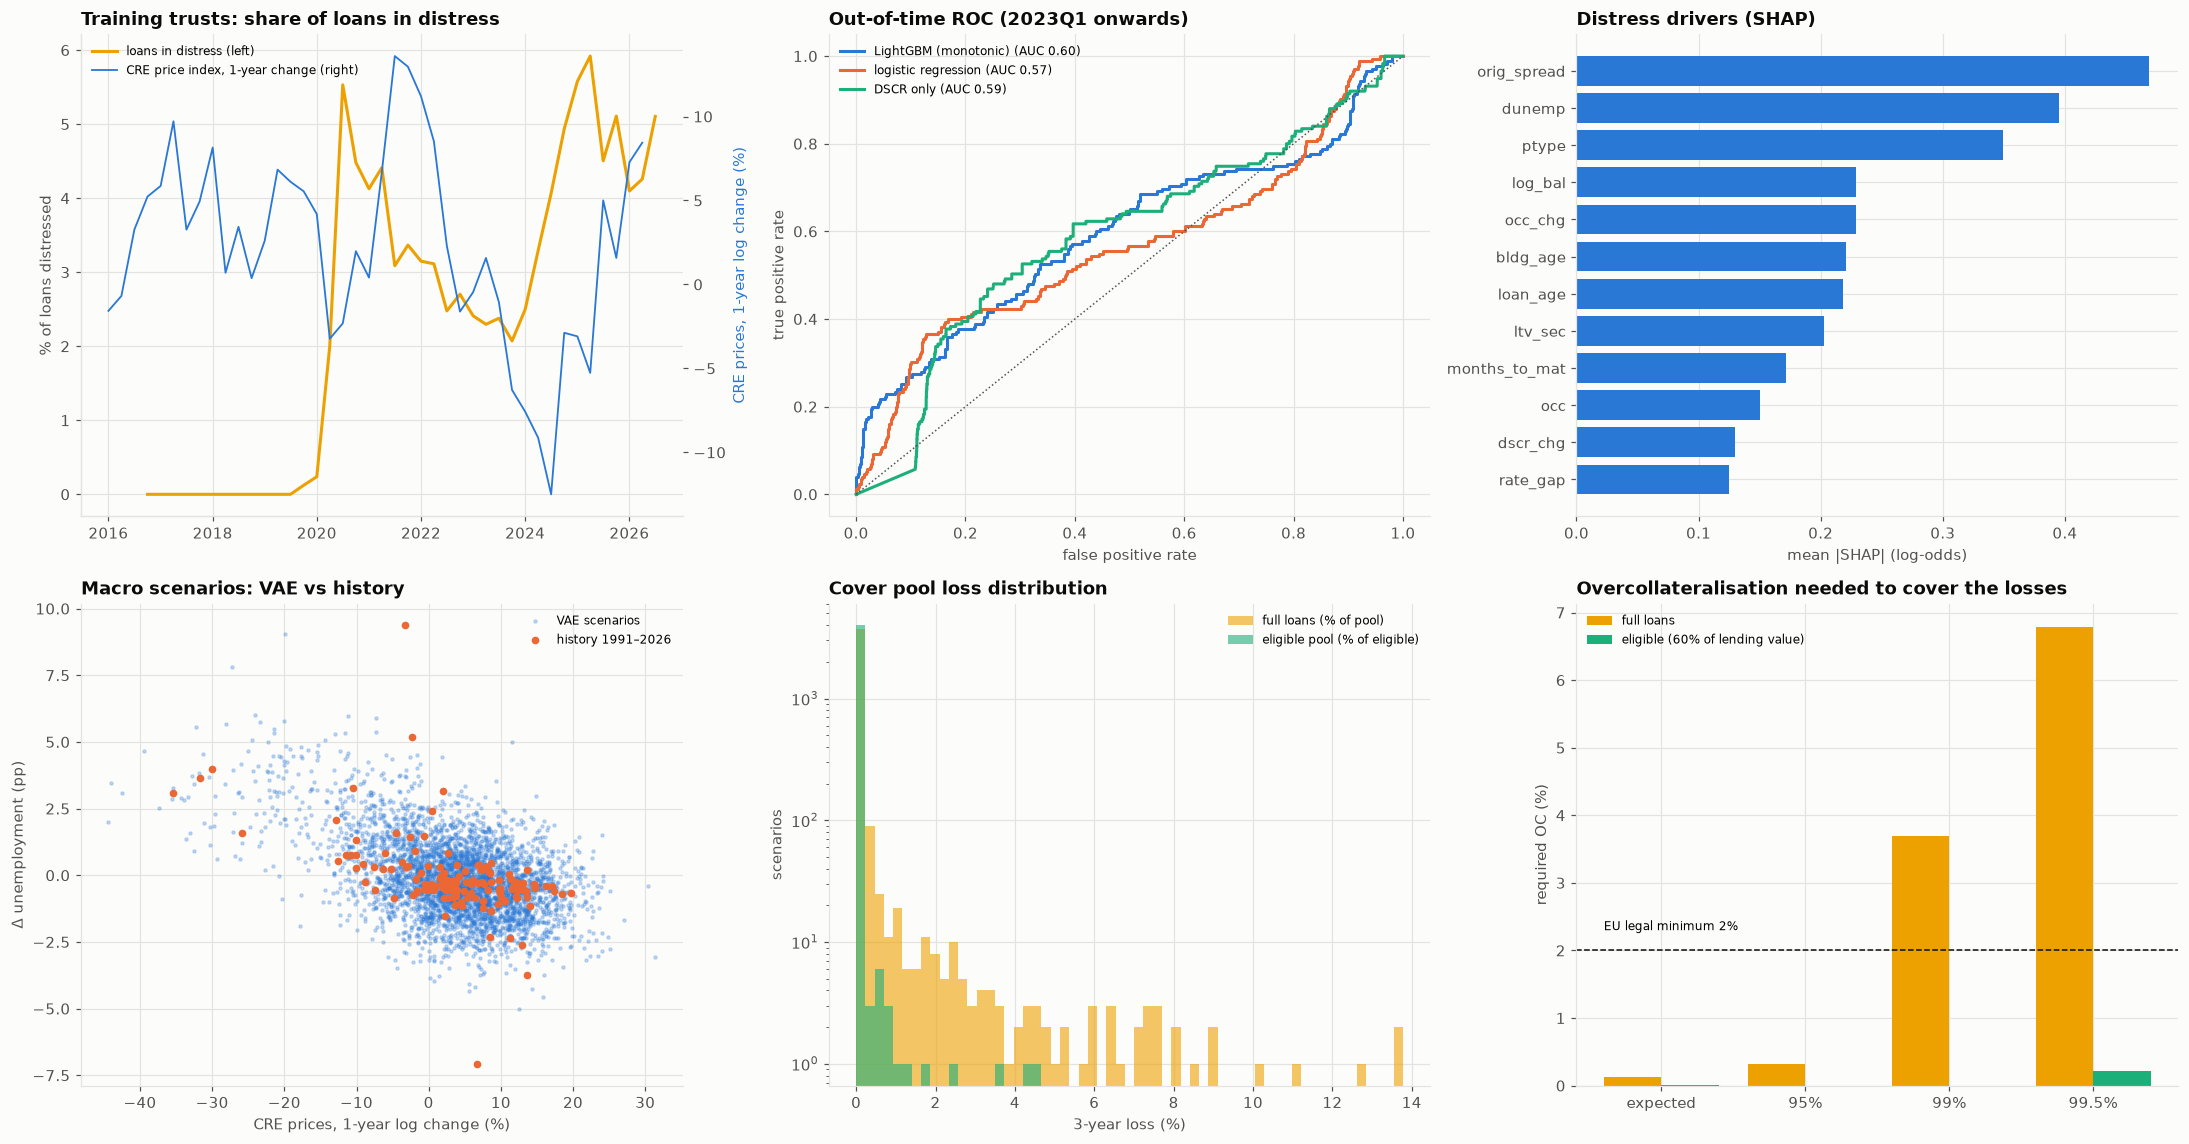

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(20, 10.5))
ax = axes[0, 0]
qr = (
    p[(p["bal"] > 0) | p["liq_code"].isin(["3", "6"]) & p["loss"].gt(0)]
    .groupby("q")["distress"]
    .mean()
    * 100
)
ax.plot(
    qr.index.to_timestamp(),
    qr.values,
    color=PALETTE[3],
    label="loans in distress (left)",
)
ax.plot(
    [],
    [],
    color=PALETTE[0],
    lw=1.2,
    label="CRE price index, 1-year change (right)",
)
ax.legend(fontsize=8, loc="upper left")
ax.set_ylabel("% of loans distressed")
ax.set_title("Training trusts: share of loans in distress")
ax2 = ax.twinx()
ax2.plot(
    MACRO["cre_yoy"].loc["2016Q1":].index.to_timestamp(),
    MACRO["cre_yoy"].loc["2016Q1":],
    color=PALETTE[0],
    lw=1.2,
)
ax2.set_ylabel("CRE prices, 1-year log change (%)", color=PALETTE[0])
ax2.grid(False)
ax = axes[0, 1]
for (k, v), c in zip([(k, v) for k, v in preds.items()], PALETTE):
    fpr, tpr, _ = roc_curve(yt, v)
    ax.plot(fpr, tpr, color=c, label=f"{k} (AUC {oot.loc[k, 'AUC']:.2f})")
ax.plot([0, 1], [0, 1], color=INK_2, ls=":", lw=1)
ax.set_xlabel("false positive rate")
ax.set_ylabel("true positive rate")
ax.set_title(f"Out-of-time ROC ({TEST_START} onwards)")
ax.legend(fontsize=8)
ax = axes[0, 2]
s12 = shap_imp.head(12)[::-1]
ax.barh(s12.index, s12.values, color=PALETTE[0])
ax.set_xlabel("mean |SHAP| (log-odds)")
ax.set_title("Distress drivers (SHAP)")
ax = axes[1, 0]
ax.scatter(
    SCEN["cre_yoy"],
    SCEN["dunemp"],
    s=4,
    alpha=0.25,
    color=PALETTE[0],
    label="VAE scenarios",
)
ax.scatter(
    H["cre_yoy"],
    H["dunemp"],
    s=16,
    color=PALETTE[1],
    label="history 1991–2026",
)
ax.set_xlabel("CRE prices, 1-year log change (%)")
ax.set_ylabel("Δ unemployment (pp)")
ax.legend(fontsize=8)
ax.set_title("Macro scenarios: VAE vs history")
ax = axes[1, 1]
bins = np.linspace(0, max(L_full.max(), L_elig.max()) / A * 100, 60)
ax.hist(
    L_full / A * 100,
    bins=bins,
    color=PALETTE[3],
    alpha=0.6,
    label="full loans (% of pool)",
)
ax.hist(
    L_elig / E * 100,
    bins=bins,
    color=PALETTE[2],
    alpha=0.6,
    label="eligible pool (% of eligible)",
)
ax.set_yscale("log")
ax.set_xlabel(f"{HORIZON_YEARS}-year loss (%)")
ax.set_ylabel("scenarios")
ax.legend(fontsize=8)
ax.set_title("Cover pool loss distribution")
ax = axes[1, 2]
xx = np.arange(len(res))
ax.bar(
    xx - 0.2,
    res["required OC, full loans (%)"],
    0.4,
    color=PALETTE[3],
    label="full loans",
)
ax.bar(
    xx + 0.2,
    res["required OC, eligible pool (%)"],
    0.4,
    color=PALETTE[2],
    label="eligible (60% of lending value)",
)
ax.axhline(2, color=INK, ls="--", lw=1)
ax.text(-0.4, 2.3, "EU legal minimum 2%", fontsize=8)
ax.set_xticks(xx)
ax.set_xticklabels(res.index)
ax.set_ylabel("required OC (%)")
ax.legend(fontsize=8)
ax.set_title("Overcollateralisation needed to cover the losses")
plt.tight_layout()
save_fig(fig, "01_cre_cover_pool_stress")
plt.show()

In [10]:
dash = make_subplots(
    rows=2,
    cols=2,
    subplot_titles=(
        "Loss distribution (full loans, % of pool)",
        "Pool balance by property type",
        "Calibration out of time (deciles)",
        "Scenario CRE move vs pool loss",
    ),
)
dash.add_trace(
    go.Histogram(
        x=L_full / A * 100, nbinsx=60, marker_color=PALETTE[3], name="loss"
    ),
    1,
    1,
)
dash.add_trace(
    go.Bar(
        x=comp.index,
        y=comp["balance_share"] * 100,
        marker_color=PALETTE[0],
        name="balance %",
    ),
    1,
    2,
)
dash.add_trace(
    go.Scatter(
        x=cal_t["predicted"] * 100,
        y=cal_t["realised"] * 100,
        mode="markers+lines",
        marker_color=PALETTE[2],
        name="deciles",
    ),
    2,
    1,
)
mx = float(max(cal_t["predicted"].max(), cal_t["realised"].max()) * 100)
dash.add_trace(
    go.Scatter(
        x=[0, mx],
        y=[0, mx],
        mode="lines",
        line=dict(dash="dot", color=INK_2),
        name="perfect",
    ),
    2,
    1,
)
dash.add_trace(
    go.Scatter(
        x=SCEN["cre_yoy"],
        y=L_full / A * 100,
        mode="markers",
        marker=dict(size=3, color=PALETTE[1], opacity=0.4),
        name="scenario",
    ),
    2,
    2,
)
dash.update_xaxes(title_text="predicted (%)", row=2, col=1)
dash.update_yaxes(title_text="realised (%)", row=2, col=1)
dash.update_xaxes(title_text="CRE prices, 1-year log change (%)", row=2, col=2)
dash.update_yaxes(title_text="loss (% of pool)", row=2, col=2)
dash.update_layout(
    height=820,
    width=1250,
    showlegend=False,
    template="simple_white",
    title="CRE cover pool stress test",
)
save_dashboard(dash, "dashboard")
dash.show()

Dashboard saved: outputs/dashboard.html and .png


## 10. Reading the results and limitations

**The distress model: strong in a known regime, weak across a regime change.**
- The training trusts' history has two distinct distress waves:
  - **2020**, Covid, led by hotels and retail;
  - **2023–2025**, rates and office, with maturity failures and special-servicing transfers.
- When random loans are held out across all periods, the monotonic LightGBM separates distressed loans very well: AUC 0.89.
- **Out of time the picture is very different**. Trained to 2021 and tested on 2023 onwards:
  - AUC 0.60 for LightGBM, 0.57 for the logit, 0.59 for a plain DSCR rule; PR-AUC 0.11 against a base rate of 0.03;
  - the model under-predicts the level: realised distress was 2.7% a year against roughly 1% predicted.
- The 2023 wave was driven by refinancing at much higher rates and by office demand. The 2017–2021 history had seen neither.
- Some events are not loan-level at all: eight multifamily loans of one sponsor, with DSCRs above 2, moved to special servicing on the same day in 2024.
- SHAP ranks:
  - the coupon spread at origination (lenders price risk they see);
  - unemployment;
  - property type (lodging is the riskiest);
  - loan size, occupancy trend, building age and loan age.
- This is the main honest finding. A loan-level PD model is a ranking tool. In a stress test the **structural refinancing test** has to carry the regime change, not the ML model alone.

**Macro scenarios.**
- Sampled from its aggregate posterior, the VAE reproduces the joint tails much better than a Gaussian:
  - the 1% CRE price fall is −25% (history −31%, Gaussian −17%);
  - unemployment rises 2.5 pp on average when CRE is in its worst 5% (history 2.2, Gaussian 1.8);
  - the CRE–unemployment correlation is −0.48 (history −0.52).
- Its worst scenarios look like 2008–2009: CRE prices down 25–31% and unemployment up 3–5 pp. Yields fall in those scenarios, which helps refinancing.

**The cover pool.**
- 538 performing loans, $12.8bn, from fifteen 2024 conduit trusts. The pool is granular: the top ten loans are 7%.
- Nearly all loans are **five-year loans maturing within the three-year horizon**. For a cover pool that is a refinancing wall.
- The mix is retail 20%, office 15%, multifamily 15%, lodging 12%, mixed use 11%. Median marked-to-market LTV is about 55–60% and DSCR about 1.5.
- Under unchanged markets about 100 loans would fail today's refinancing test (interest-only DSCR ≥ 1.25 at the 10-year + 2%, LTV ≤ 75%). Values cover their balances, so the expected loss is essentially zero.

**Losses and required overcollateralisation.**
- Three-year loss on the full loans:
  - 0.14% expected and 0.32% at the 95th percentile;
  - **3.6% at the 99th and 6.4% at the 99.5th**;
  - so the pool needs **3.7% OC at 99% and 6.8% at 99.5%**, well above the EU 2% legal minimum.
- The loss distribution is extremely skewed. Losses appear only when values fall far enough that refinancing failures turn into losses, about 300 of the 330 defaults in the worst 1% of scenarios.
- Office carries 29% of the 99th-percentile loss for 15% of the balance; retail and lodging follow.
- **The Pfandbrief-style eligibility cap removes almost all of it.** Counting each loan only up to 60% of an 85% lending value leaves 86% of the balance eligible, and the eligible pool loses 0.2% even at the 99.5th percentile. The senior recovery claim on the property absorbs a 30% value fall.
- That is the economic logic of LTV caps in covered bond law: the excess over the cap stays on the issuer's balance sheet, not in the cover pool.

**Limitations.**
- US conduit CMBS are a proxy for European cover-pool CRE. Covered bond loans are usually balance-sheet loans with recourse and relationship lenders that extend rather than foreclose. The 100% default-on-refinancing-failure assumption is therefore conservative.
- Training covers only 14 trusts, 102 distressed loans and one decade.
- Multi-property and pari passu loans are approximated: whole-loan balances are inferred from debt service, and implausible LTVs are reset to 65%.
- Property-type value and NOI sensitivities, liquidation costs (25%), the lending-value haircut and the refinancing criteria are stated assumptions.
- Defaults are independent given the macro scenario. Sponsor-level correlation, like the 2024 portfolio transfer above, would fatten the tail further.
- The macro scenario is applied as a single one-year move over a three-year horizon, with no recovery path.

In [11]:
oot.to_csv(OUT_DIR / "distress_model_out_of_time.csv")
cal_t.to_csv(OUT_DIR / "distress_model_calibration.csv")
shap_imp.to_csv(
    OUT_DIR / "distress_shap_importance.csv", header=["mean_abs_shap"]
)
tails.to_csv(OUT_DIR / "macro_scenario_tails.csv")
SCEN.to_csv(OUT_DIR / "vae_macro_scenarios.csv", index=False)
res.to_csv(OUT_DIR / "cover_pool_loss_and_required_oc.csv")
comp.to_csv(OUT_DIR / "cover_pool_by_property_type.csv")
print(
    "Outputs written:", ", ".join(sorted(p_.name for p_ in OUT_DIR.iterdir()))
)

Outputs written: 01_cre_cover_pool_stress.png, cover_pool_by_property_type.csv, cover_pool_loss_and_required_oc.csv, dashboard.html, dashboard.png, distress_model_calibration.csv, distress_model_out_of_time.csv, distress_shap_importance.csv, macro_scenario_tails.csv, vae_macro_scenarios.csv


## References

### Finance and regulation

- European Parliament & Council of the European Union. (2019). *Directive (EU) 2019/2162 on the issue of covered bonds and covered bond public supervision*. https://eur-lex.europa.eu/eli/dir/2019/2162/oj
- Black, L., Chu, C. S., Cohen, A., & Nichols, J. B. (2012). Differences across originators in CMBS loan underwriting. *Journal of Financial Services Research, 42*(1–2), 115–134. https://doi.org/10.1007/s10693-011-0120-0
- Ambrose, B. W., & Sanders, A. B. (2003). Commercial mortgage-backed securities: Prepayment and default. *The Journal of Real Estate Finance and Economics, 26*(2–3), 179–196. https://doi.org/10.1023/A:1022978708728
- Packer, F., Stever, R., & Upper, C. (2007). The covered bond market. *BIS Quarterly Review*, September, 43–55. https://www.bis.org/publ/qtrpdf/r_qt0709f.htm

### Machine learning and deep learning

- Kingma, D. P., & Welling, M. (2014). Auto-encoding variational Bayes. In *Proceedings of the 2nd International Conference on Learning Representations*. https://arxiv.org/abs/1312.6114
- Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., & Liu, T.-Y. (2017). LightGBM: A highly efficient gradient boosting decision tree. *Advances in Neural Information Processing Systems, 30*. https://proceedings.neurips.cc/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html
- Lundberg, S. M., & Lee, S.-I. (2017). A unified approach to interpreting model predictions. *Advances in Neural Information Processing Systems, 30*. https://arxiv.org/abs/1705.07874